# 07 — Middleware həddi: FPR / recall və yanlış bloklanan təmiz girişlər

ML middleware-in `threshold` parametri bloklama həddidir. Bu notebook:
1. hədd **0.5 / 0.7 / 0.9** üçün test dəstində recall, FPR (bütün + adi giriş) və F1,
2. ML-in yanlış blokladığı **təmiz istifadəçi girişlərini** (adlar, e-poçtlar, ünvanlar) göstərir.

Model `models/lr_norm_aug_v2.joblib`-dir (JS middleware ilə eyni; parity < 1e-6 sübut olunub), ona görə hesablama
Python-da aparılır və nəticə JS middleware-ə birbaşa tətbiq olunur.

## 0. Mühit

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
RES_DIR, FIG_DIR, MODEL_DIR, PROC_DIR = ROOT / "results", ROOT / "figures", ROOT / "models", ROOT / "data/processed"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})
save_fig = lambda fig, n: fig.savefig(FIG_DIR / n, dpi=300, bbox_inches="tight")

model = joblib.load(MODEL_DIR / "lr_norm_aug_v2.joblib")
test = pd.read_csv(PROC_DIR / "test_v2.csv", keep_default_na=False, dtype={"Query": str, "Label": int})
proba = model.predict_proba(test.Query)[:, 1]
print("test:", len(test), "zərərli:", int(test.Label.sum()))

test: 4539 zərərli: 1745


## 1. Hədd analizi
`is_stmt` = tam SQL ifadəsi olan təmiz sorğular (datasetin təmiz sinfinin böyük hissəsi); veb formada istifadəçi belə
giriş göndərmədiyi üçün FPR həm bütün təmiz sorğularda, həm də yalnız "adi giriş" (SQL ifadəsi olmayan) sorğularda hesablanır.

In [2]:
import re
SQL_STMT_RE = r"^\s*\(?\s*(select|insert|update|delete|create|drop|alter|with|exec|truncate|grant)\b"
is_stmt = test.Query.str.contains(SQL_STMT_RE, case=False, regex=True)
plain = (test.Label == 0) & ~is_stmt
y = test.Label.to_numpy()

rows = []
for thr in (0.5, 0.7, 0.9):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    rows.append({
        "threshold": thr,
        "recall": recall_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred),
        "fpr_all": fp / (fp + tn),
        "fpr_plain_input": pred[plain.to_numpy()].mean(),
        "fp_all": int(fp), "fn": int(fn),
    })
thr_table = pd.DataFrame(rows).set_index("threshold")
thr_table.to_csv(RES_DIR / "middleware_threshold.csv")
display(thr_table.style.format({"recall": "{:.4f}", "precision": "{:.4f}", "f1": "{:.4f}",
                                "fpr_all": "{:.4f}", "fpr_plain_input": "{:.4f}"}))

C:\Users\Mehman\AppData\Local\Temp\ipykernel_17108\3995203963.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  is_stmt = test.Query.str.contains(SQL_STMT_RE, case=False, regex=True)


,recall,precision,f1,fpr_all,fpr_plain_input,fp_all,fn
threshold,,,,,,,
0.500000,0.9937,0.9988,0.9963,0.0007,0.0009,2,11
0.700000,0.9937,0.9994,0.9966,0.0004,0.0000,1,11
0.900000,0.9874,0.9994,0.9934,0.0004,0.0000,1,22


## 2. Recall–FPR əyrisi və hədd nöqtələri

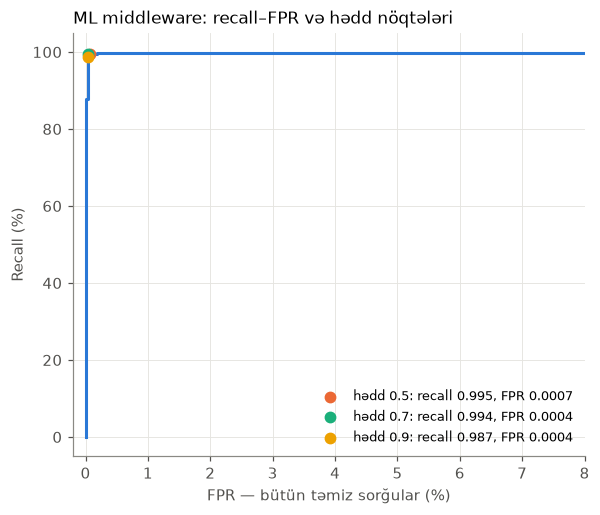

In [3]:
from sklearn.metrics import roc_curve
fpr, tpr, thr = roc_curve(y, proba)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr * 100, tpr * 100, color="#2a78d6", linewidth=2)
for t, c in zip((0.5, 0.7, 0.9), ("#eb6834", "#1baf7a", "#eda100")):
    i = np.argmin(np.abs(thr - t))
    ax.scatter(fpr[i] * 100, tpr[i] * 100, color=c, zorder=5, s=45,
               label=f"hədd {t}: recall {tpr[i]:.3f}, FPR {fpr[i]:.4f}")
ax.set_xlabel("FPR — bütün təmiz sorğular (%)")
ax.set_ylabel("Recall (%)")
ax.set_xlim(-0.2, 8)
ax.set_title("ML middleware: recall–FPR və hədd nöqtələri", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
save_fig(fig, "07_threshold_roc.png")
plt.show()

## 3. Yanlış bloklanan təmiz istifadəçi girişləri
Təmiz sinifdən hədd 0.5-də bloklanan adi girişlər (SQL ifadəsi olmayanlar). Giriş tipini təxmin edirik
(e-poçt / ad / ünvan / digər) ki, hansı real istifadəçi məlumatlarının yanlış bloklandığı görünsün.

In [4]:
def guess_kind(q):
    if re.search(r"[\w.+-]+@[\w-]+\.[\w.-]+", q):
        return "e-poçt"
    if re.search(r"\d+\s*[,-]|\bst\b|\bstreet\b|\bave\b|calle|\d{4,}", q, re.I):
        return "ünvan / nömrə"
    if re.fullmatch(r"[A-Za-zÀ-ÿ'’.\- ]{2,40}", q):
        return "ad"
    return "digər"

fp_plain = test[plain & (proba >= 0.5)].copy()
fp_plain["score"] = proba[plain.to_numpy() & (proba >= 0.5)]
fp_plain["kind"] = fp_plain.Query.map(guess_kind)
print(f"Adi girişlərdə hədd 0.5-də yanlış bloklanan: {len(fp_plain)} / {int(plain.sum())}")
display(fp_plain["kind"].value_counts().rename("say").to_frame())
display(fp_plain.sort_values("score", ascending=False)[["Query", "kind", "score"]].head(20).reset_index(drop=True))
fp_plain[["Query", "kind", "score"]].to_csv(RES_DIR / "middleware_false_blocks.csv", index=False)

# Həddin FP-yə təsiri (adi girişlər)
drop = pd.DataFrame({t: [int((proba[plain.to_numpy()] >= t).sum())] for t in (0.5, 0.7, 0.9)}, index=["yanlış blok (adi giriş)"])
display(drop)

Adi girişlərdə hədd 0.5-də yanlış bloklanan: 1 / 1120


,say
kind,
ad,1


,Query,kind,score
0,sandler,ad,0.547771


,0.5,0.7,0.9
yanlış blok (adi giriş),1,0,0
